# 05.9 · AutoML in industry: PyCaret, and what it automates

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/09-automl-pycaret/lesson.ipynb)

**Optional lesson.** Read the [README](README.md) first.

You have spent Modules 02–05 building every step by hand: preprocessing pipelines, cross-validated comparisons, tuning, explanations, saving. Many teams use **AutoML** tools to do those steps in a few lines when they need a fast baseline. This notebook shows PyCaret doing exactly what you already know, step by step, and then the same thing in plain scikit-learn.

> **Environment note.** PyCaret 3.3 (the current release) only runs on Python 3.9–3.11 and pins older library versions. The course uses Python 3.12, and Google Colab now does too. So the PyCaret cells need their **own** Python 3.11 environment (see `setup/requirements-pycaret.txt`). In the main course environment they are skipped automatically; section 3 runs everywhere.

## 0. Is PyCaret available?

In [1]:
import sys
try:
    import pycaret
    HAS_PYCARET = True
    print("PyCaret", pycaret.__version__, "on Python", sys.version.split()[0])
except Exception as e:                       # ImportError, or RuntimeError on Python 3.12+
    HAS_PYCARET = False
    print(f"PyCaret not available here (Python {sys.version.split()[0]}): {type(e).__name__}")
    print("The PyCaret cells below will be skipped. Run this notebook in the separate Python 3.11")
    print("environment described in setup/requirements-pycaret.txt to see them work.")
    print("Section 3 (the same steps in plain scikit-learn) runs everywhere.")

PyCaret not available here (Python 3.12.16): ModuleNotFoundError
The PyCaret cells below will be skipped. Run this notebook in the separate Python 3.11
environment described in setup/requirements-pycaret.txt to see them work.
Section 3 (the same steps in plain scikit-learn) runs everywhere.


## 1. The churn table (same as every Module 05 lesson)

In [2]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


## 2. PyCaret, step by step

Each cell is labelled with the lesson where you learned to do it by hand.

### 2a. `setup()` ↔ Module 04 preprocessing pipeline

`setup` inspects the columns, builds a preprocessing pipeline (imputation, scaling, encoding), and fixes the CV folds. It only sees the training customers.

In [3]:
if HAS_PYCARET:
    from pycaret.classification import (setup, compare_models, create_model, tune_model,
                                        interpret_model, finalize_model, save_model, predict_model, pull)
    exp = setup(data=X_train.assign(churned=y_train), target="churned", session_id=42,
                fold=5, normalize=True, verbose=False, system_log=False)
    print(exp.pipeline)                     # the preprocessing pipeline it built for you

### 2b. `compare_models()` ↔ the 05.10 leaderboard

Trains each model with 5-fold CV and returns a leaderboard. We restrict it to models you know, so it runs in about a minute.

In [4]:
if HAS_PYCARET:
    best = compare_models(include=["lr", "dt", "knn", "rf", "et", "gbc", "lightgbm"],
                          sort="AUC", verbose=False)
    leaderboard = pull()
    print(leaderboard[["Model", "Accuracy", "AUC", "Recall", "Prec.", "F1", "TT (Sec)"]].round(3).to_string())

### 2c. `tune_model()` ↔ 05.6 random search

Random search over a built-in grid for the chosen model, scored by CV AUC. `n_iter` is the budget.

In [5]:
if HAS_PYCARET:
    lgbm = create_model("lightgbm", verbose=False)
    tuned = tune_model(lgbm, optimize="AUC", n_iter=20, verbose=False)
    print(pull().loc[["Mean", "Std"], ["AUC"]].round(3))

### 2d. `interpret_model()` ↔ 05.8 SHAP

For tree models, PyCaret calls SHAP and draws the same beeswarm you built yourself.

In [6]:
if HAS_PYCARET:
    interpret_model(tuned)

### 2e. `finalize_model()` + `save_model()` ↔ 05.10 saving a bundle

`finalize_model` refits on all training data; `save_model` writes the pipeline and model in one file.

In [7]:
if HAS_PYCARET:
    from pathlib import Path
    from sklearn.metrics import roc_auc_score
    final = finalize_model(tuned)
    Path("../../../models").mkdir(exist_ok=True)
    save_model(final, "../../../models/churn_pycaret_lightgbm", verbose=False)
    scored = predict_model(final, data=X_test, raw_score=True, verbose=False)
    print(f"test AUC {roc_auc_score(y_test, scored['prediction_score_1']):.3f}")

## 3. The same thing without PyCaret

Everything above in plain scikit-learn, using only what you learned in Modules 04–05. This section runs in the main course environment.

In [8]:
import time, lightgbm as lgb
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(5, shuffle=True, random_state=42)                   # setup(): fixed folds
prep = lambda m: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), m)   # setup(): preprocessing

In [9]:
zoo = {"Logistic Regression": LogisticRegression(max_iter=1000),
       "Decision Tree": DecisionTreeClassifier(random_state=42),
       "K Neighbors": KNeighborsClassifier(),
       "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
       "Extra Trees": ExtraTreesClassifier(random_state=42, n_jobs=-1),
       "Gradient Boosting": GradientBoostingClassifier(random_state=42),
       "LightGBM": lgb.LGBMClassifier(verbose=-1, random_state=42, n_jobs=1)}
rows = []
for name, m in zoo.items():                                                # compare_models()
    r = cross_validate(prep(m), X_train, y_train, cv=cv, scoring=["accuracy", "roc_auc", "f1"])
    rows.append({"Model": name, "Accuracy": r["test_accuracy"].mean(), "AUC": r["test_roc_auc"].mean(),
                 "F1": r["test_f1"].mean(), "TT (Sec)": r["fit_time"].mean()})
pd.DataFrame(rows).sort_values("AUC", ascending=False).set_index("Model").round(3)

,Accuracy,AUC,F1,TT (Sec)
Model,,,,
Logistic Regression,0.685,0.740,0.650,0.003
Gradient Boosting,0.663,0.730,0.625,0.117
Random Forest,0.639,0.712,0.571,0.063
LightGBM,0.637,0.703,0.580,0.021
Extra Trees,0.631,0.694,0.556,0.047
K Neighbors,0.643,0.693,0.588,0.002
Decision Tree,0.601,0.594,0.540,0.005


Same shape of table as PyCaret's, from about 15 lines you fully understand, and the same story: logistic regression on top, the unlimited-depth decision tree last, default LightGBM mid-table because its defaults overfit this small table (05.6). When run in the PyCaret environment, PyCaret's leaderboard has the same top and bottom; it uses the same libraries underneath. (Its exact numbers differ slightly because it draws different CV folds.)

In [10]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint
tuned_sk = RandomizedSearchCV(                                              # tune_model()
    prep(lgb.LGBMClassifier(n_estimators=200, verbose=-1, random_state=42, n_jobs=1)),
    {"lgbmclassifier__learning_rate": loguniform(0.005, 0.3),
     "lgbmclassifier__num_leaves": randint(2, 64),
     "lgbmclassifier__min_child_samples": randint(5, 100)},
    n_iter=20, cv=cv, scoring="roc_auc", random_state=42, n_jobs=-1).fit(X_train, y_train)
print(f"tuned LightGBM, CV AUC {tuned_sk.best_score_:.3f}")

tuned LightGBM, CV AUC 0.742


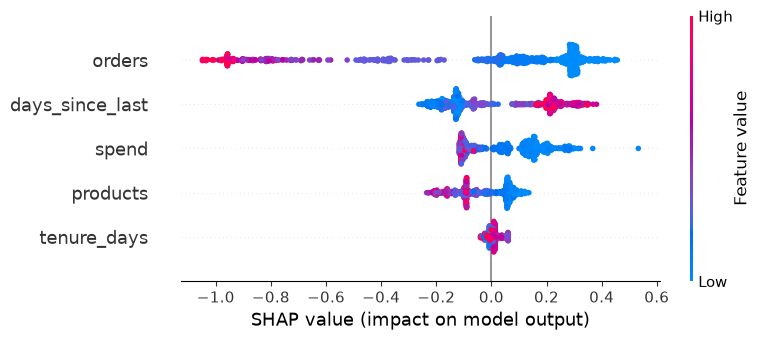

In [11]:
import shap                                                                  # interpret_model()
booster = tuned_sk.best_estimator_[-1]
X_scaled = tuned_sk.best_estimator_[:-1].transform(X_test)
sv = shap.TreeExplainer(booster)(pd.DataFrame(X_scaled, columns=features, index=X_test.index))
shap.plots.beeswarm(sv, show=False); plt.tight_layout(); plt.show()

In [12]:
import joblib                                                                 # finalize_model() + save_model()
from pathlib import Path
from sklearn.metrics import roc_auc_score
models = Path("../../../models"); models.mkdir(exist_ok=True)
joblib.dump(tuned_sk.best_estimator_, models / "churn_sklearn_lightgbm.joblib")
print(f"test AUC {roc_auc_score(y_test, tuned_sk.predict_proba(X_test)[:, 1]):.3f}")

test AUC 0.734


## 4. When to use which

| Situation | Reach for |
|---|---|
| First hour on a new tabular problem: "is there any signal at all?" | AutoML (PyCaret, FLAML, AutoGluon) |
| A stakeholder wants a rough number by tomorrow | AutoML, clearly labelled as a baseline |
| The model will go to production | Your own pipeline: you must know every step, pin every version, and debug it at 3 a.m. |
| Something looks too good, or wrong | Your own pipeline: AutoML can hide leakage just as well as it hides boilerplate |
| Learning ML | By hand first (as in this course), AutoML afterwards |

AutoML automates the **typing**, not the **thinking**. It cannot tell you that `recency_days` leaks the future (01.9), that accuracy lies on a 5% target (05.7), or that a £5 voucher should go to 94% of customers (05.10). You can.

## Quiz answers

1. `setup()` builds the preprocessing pipeline and fixes the CV folds (Module 04); `compare_models()` is a cross-validated leaderboard (05.10); `tune_model()` is a random search (05.6); `interpret_model()` is SHAP (05.8); `finalize_model()`/`save_model()` is refit-and-save (05.10).
2. For quick baselines, prototyping, and checking whether a dataset has any signal before investing time.
3. It hides choices (preprocessing, defaults, CV scheme) that you need to understand to debug or defend the model, it pins old library versions, and it cannot catch leakage or business-logic mistakes.
4. Same data, same folds, and the same underlying libraries (scikit-learn, LightGBM). AutoML is a convenience layer, not a different algorithm.
5. A separate virtual environment with Python 3.11 and the versions in `setup/requirements-pycaret.txt`, so its pinned dependencies do not break the main course environment.

**Next:** [05.10 Choosing and saving the final model](../10-choosing-and-saving/)